In [1]:
import pySISF

print(pySISF.__version__)

0.7.0


In [2]:
import os
import numpy as np

np.__version__

'2.1.3'

## Example 1: writing a 3D image to a SISF file

In [3]:
# Step 1: Create a 3D image as a NumPy array (this is just an example, you can use your own data)
data = np.arange(500**3, dtype='uint16').reshape(500, 500, 500)

In [4]:
# Step 2: Write the data to a SISF file
pySISF.sisf.create_sisf(
    'example.sisf', # Output file name
    data, # The 3D image data as a NumPy array
    data.shape, # Metachunk size (set to size of image for single metachunk)
    [32]*3, # Chunk size (32x32x32)
    (1,1,1), # Voxel size (1nm, 1nm, 1nm)
    compression=1, # Use ZSTD compression
    enable_status=True, # Print progress status
    thread_count=10, # Use 10 threads for conversion
)

100%|██████████| 1/1 [00:00<00:00,  1.82it/s]


In [5]:
# Step 3: Check size of folder after conversion

def get_folder_size(path):
    total = 0
    for dirpath, _, filenames in os.walk(path):
        for filename in filenames:
            filepath = os.path.join(dirpath, filename)
            if not os.path.islink(filepath):
                total += os.path.getsize(filepath)
    return total


size_bytes = get_folder_size("example.sisf")
print(f"example.sisf total size: {size_bytes:,} bytes ({size_bytes / 1024**2:.2f} MiB)")
print(f'Compression ratio: {data.nbytes / size_bytes:.2f}x')

example.sisf total size: 167,389,657 bytes (159.64 MiB)
Compression ratio: 1.49x


## Example 2: Reading from a SISF file

In [6]:
# Step 1: Open an existing SISF file created above
img = pySISF.sisf.sisf('example.sisf')

In [7]:
# Step 2: Check on the size using numpy-like interface
print(img.shape) # C, X, Y, Z

(1, 500, 500, 500)


In [8]:
%%timeit
# Step 3: Read a portion of the data
# `timeit` is used here to benchmark the read speed by repeating the read operation multiple times and measuring the average time taken.

img[0,0,:,:]

10.1 ms ± 537 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [9]:
result = img[0,0,:,:]
print(result.shape)

(1, 1, 500, 500)


## Example 3: Plotting the contents of a image read

In [10]:
import matplotlib.pyplot as plt

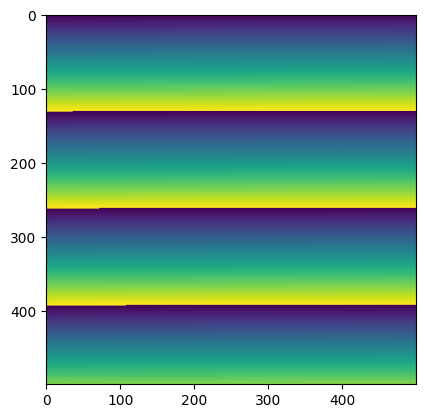

In [11]:
# Step 1: Create a plot of the image
# The squeeze operation is used to remove any singleton dimensions from the result, ensuring that the data is in the correct format for plotting. The imshow function is then used to display the 2D image, and plt.show() renders the plot on the screen.

plt.imshow(np.squeeze(result[0,0,:,:]))
plt.show()